In [1]:
import sys
from pathlib import Path

project_path = Path("..").resolve()
sys.path.append(str(project_path))

import numpy as np
import matplotlib.pyplot as plt

from src.data.class_analysis import (
    load_all_masks,
    compute_voxel_class_statistics,
    find_extreme_masks,
    print_statistics,
    plot_class_distribution,
    plot_class_distribution_per_patch,
    plot_extreme_masks,
    generate_report
)


In [2]:
#  Load all masks from USEFUL PATCHES directory
mask_dir = Path("../data/raw/patches_64/useful_patches/masks")

print("=" * 60)
print("CLASS DISTRIBUTION ANALYSIS - USEFUL PATCHES ONLY")
print("=" * 60)
print(f"Loading masks from: {mask_dir}")
masks, filenames = load_all_masks(mask_dir, max_masks=None)

print(f"Loaded {len(masks)} masks")
print(f"First 5 masks: {filenames[:5]}")


CLASS DISTRIBUTION ANALYSIS - USEFUL PATCHES ONLY
Loading masks from: ../data/raw/patches_64/useful_patches/masks
Loaded 1772 masks
First 5 masks: ['patch_64_00000001.npy', 'patch_64_00000002.npy', 'patch_64_00000003.npy', 'patch_64_00000004.npy', 'patch_64_00000005.npy']


In [3]:
#  Check values in masks (should be only 0 and 255)
print("\nChecking mask values:")
has_neurons_count = 0
for i in range(min(10, len(masks))):
    unique_vals = np.unique(masks[i])
    neuron_count = np.sum(masks[i] == 255)
    if neuron_count > 0:
        has_neurons_count += 1
    print(f"  {filenames[i]}: unique values = {unique_vals}, neurons = {neuron_count}")

print(f"\nFirst 10 masks: {has_neurons_count} contain neurons, {10 - has_neurons_count} are vessels-only")



Checking mask values:
  patch_64_00000001.npy: unique values = [  0 255], neurons = 673
  patch_64_00000002.npy: unique values = [  0 255], neurons = 951
  patch_64_00000003.npy: unique values = [  0 255], neurons = 1354
  patch_64_00000004.npy: unique values = [  0 255], neurons = 413
  patch_64_00000005.npy: unique values = [  0 255], neurons = 156
  patch_64_00000006.npy: unique values = [  0 255], neurons = 283
  patch_64_00000008.npy: unique values = [  0 255], neurons = 7
  patch_64_00000009.npy: unique values = [  0 255], neurons = 1010
  patch_64_00000010.npy: unique values = [  0 255], neurons = 1249
  patch_64_00000011.npy: unique values = [  0 255], neurons = 1247

First 10 masks: 10 contain neurons, 0 are vessels-only


In [4]:
#  Compute voxel class statistics on USEFUL patches
stats = compute_voxel_class_statistics(masks)
print_statistics(stats)

VOXEL CLASS DISTRIBUTION ANALYSIS

Number of patches analyzed: 1772
Patches containing neurons: 1739
Patches without neurons (pure background): 33

Total voxels across all patches:
  Total voxels: 464,519,168
  Class 0 (background, bruit, artefacts): 463,783,842 (99.8417%)
  Class 255 (neurones): 735,326 (0.158298%)

Class ratio (Class 0 / Class 255): 1 : 630.72

Per patch statistics (voxels class 255 = neurones):
  Min voxels per patch: 0
  Max voxels per patch: 6,849
  Mean voxels per patch: 414.97
  Median voxels per patch: 181.00
  Std voxels per patch: 654.26



In [5]:
#  Find extreme masks within USEFUL patches
extreme_info = find_extreme_masks(masks, filenames, stats["class_255_per_mask"])

print("\n" + "=" * 60)
print("EXTREME CASES WITHIN USEFUL PATCHES")
print("=" * 60)
print(f"  Most neuron voxels: {extreme_info['max_neurons_voxels']['filename']} - {extreme_info['max_neurons_voxels']['voxel_count']:,} voxels")
if extreme_info['min_neurons_voxels_nonzero']['voxel_count'] is not None:
    print(f"  Least neuron voxels (non-zero): {extreme_info['min_neurons_voxels_nonzero']['filename']} - {extreme_info['min_neurons_voxels_nonzero']['voxel_count']:,} voxels")
print(f"  Vessels-only patches (zero neuron voxels): {extreme_info['zero_neurons']['count']} patches")



EXTREME CASES WITHIN USEFUL PATCHES
  Most neuron voxels: patch_64_00000348.npy - 6,849 voxels
  Least neuron voxels (non-zero): patch_64_00001562.npy - 1 voxels
  Vessels-only patches (zero neuron voxels): 33 patches


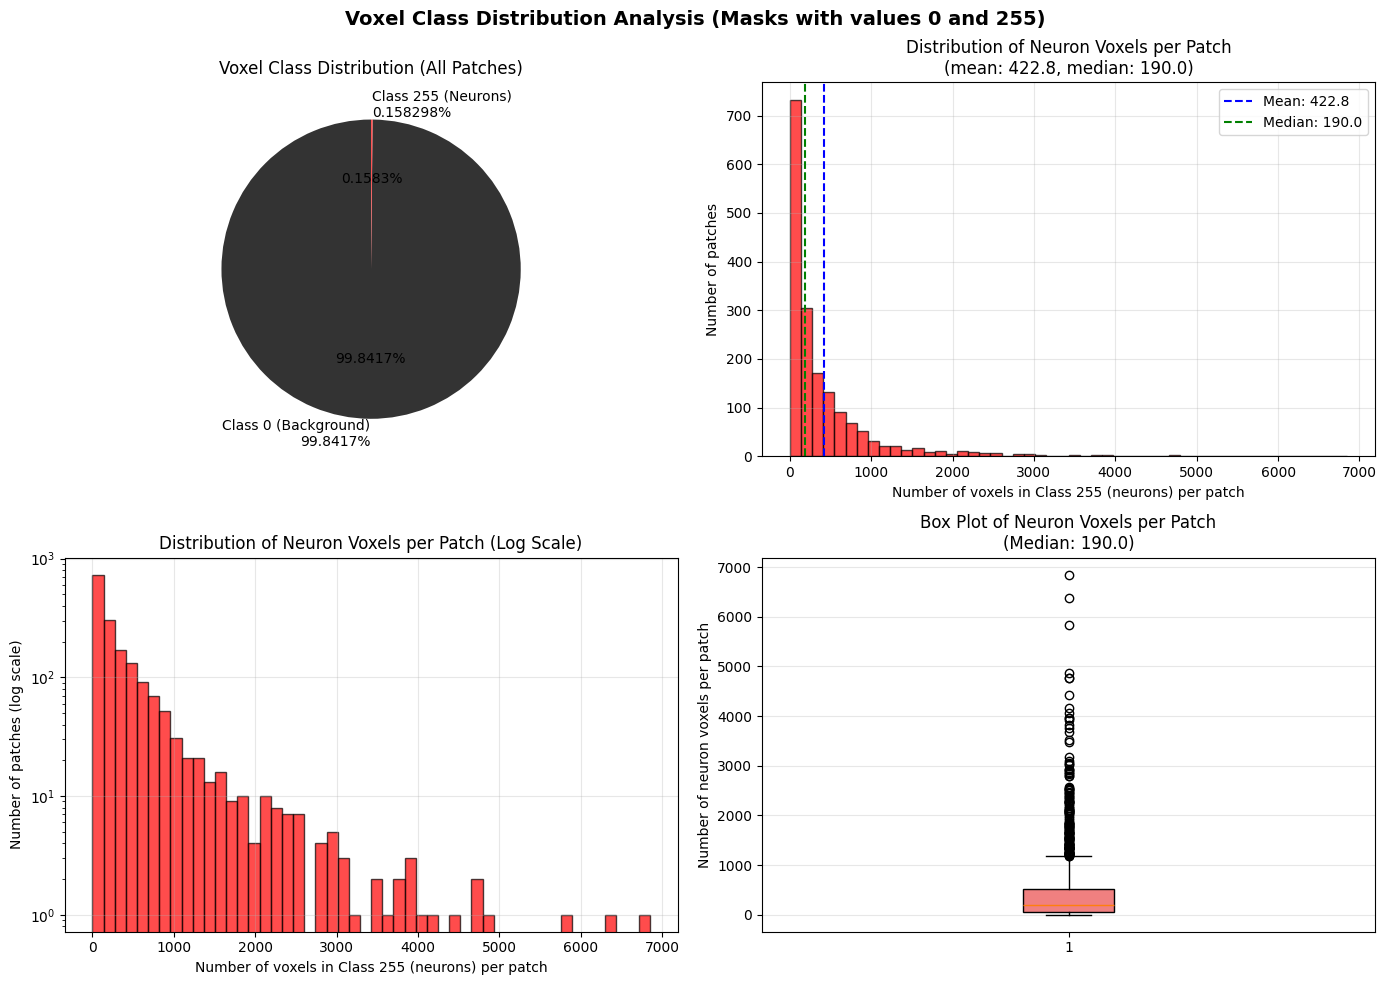

In [6]:
#  Plot class distribution for USEFUL patches
plot_class_distribution(stats, save_path="../outputs/useful_voxel_class_distribution.png")

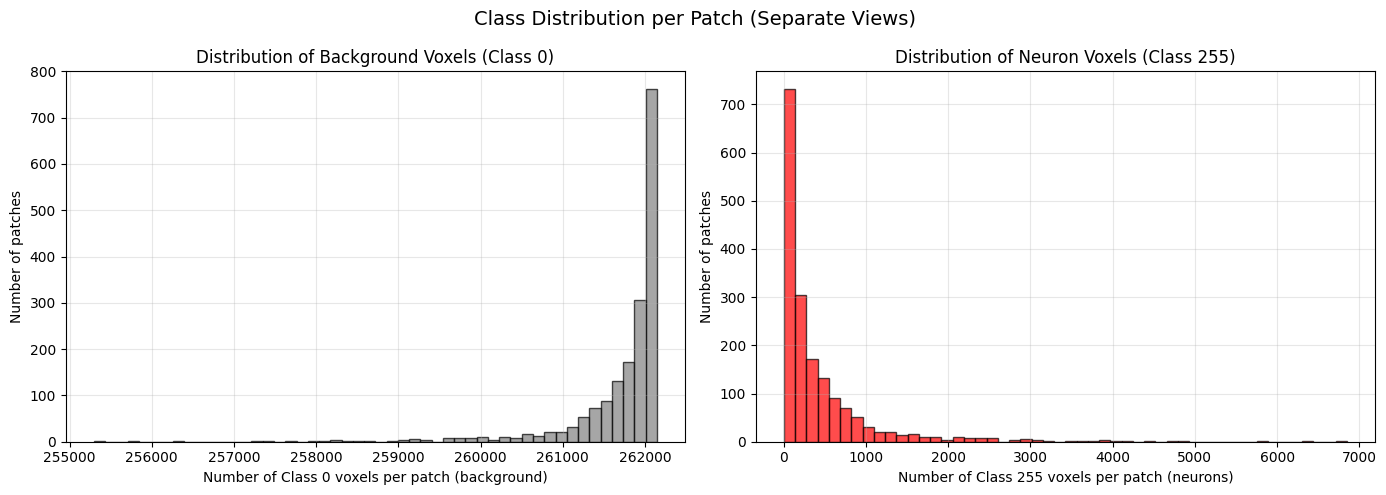

In [7]:
#  Plot class distribution per patch (separate views)
plot_class_distribution_per_patch(stats)

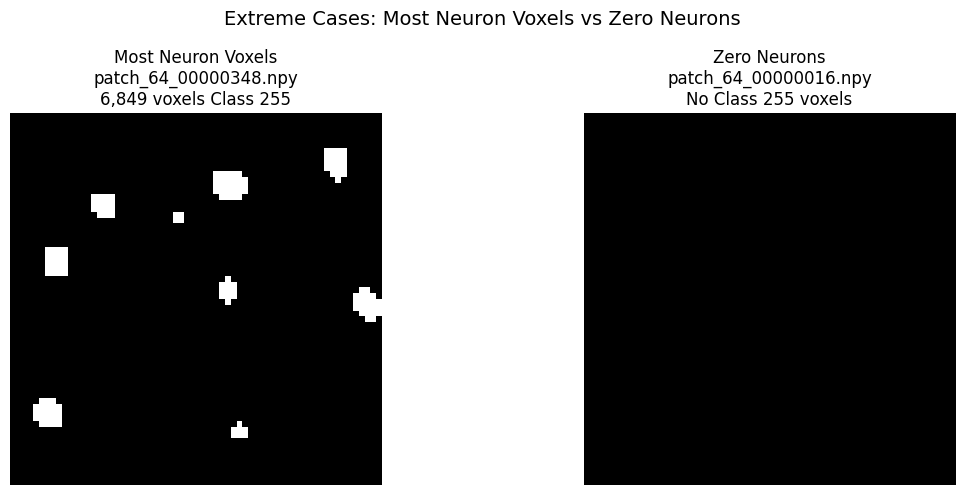

In [8]:
#  Plot extreme masks from USEFUL patches
plot_extreme_masks(masks, filenames, extreme_info, num_display=4)

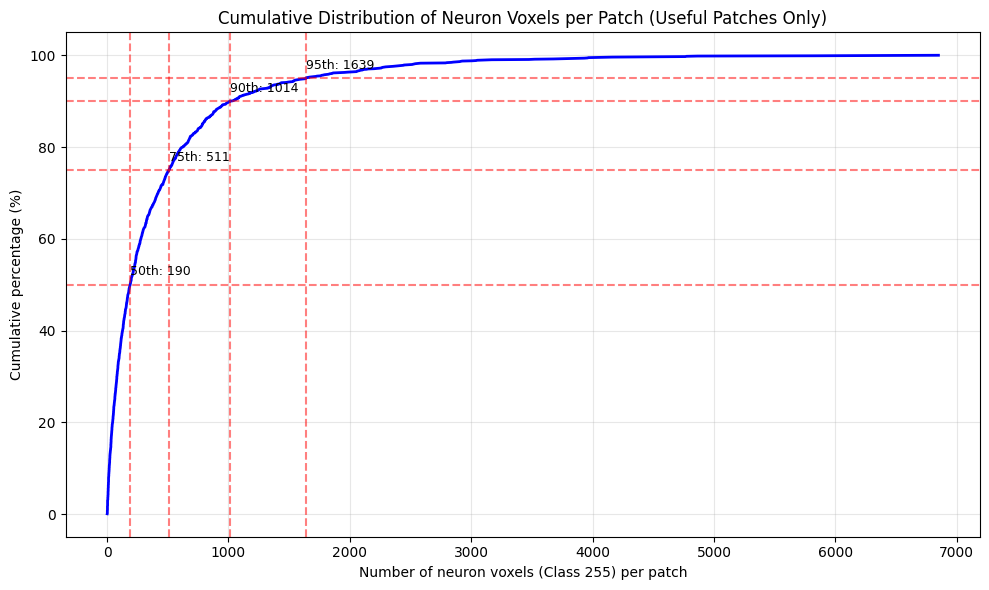

In [9]:
#  Cumulative distribution of neuron voxels per patch (only useful patches)
class_255_nonzero = [c for c in stats['class_255_per_mask'] if c > 0]
if len(class_255_nonzero) > 0:
    sorted_voxels = np.sort(class_255_nonzero)
    cumulative = np.arange(1, len(sorted_voxels) + 1) / len(sorted_voxels) * 100
    
    plt.figure(figsize=(10, 6))
    plt.plot(sorted_voxels, cumulative, 'b-', linewidth=2)
    plt.xlabel('Number of neuron voxels (Class 255) per patch')
    plt.ylabel('Cumulative percentage (%)')
    plt.title('Cumulative Distribution of Neuron Voxels per Patch (Useful Patches Only)')
    plt.grid(True, alpha=0.3)
    
    # Add percentile lines
    for p in [50, 75, 90, 95]:
        perc_value = np.percentile(class_255_nonzero, p)
        plt.axhline(y=p, color='r', linestyle='--', alpha=0.5)
        plt.axvline(x=perc_value, color='r', linestyle='--', alpha=0.5)
        plt.text(perc_value, p + 2, f'{p}th: {perc_value:.0f}', fontsize=9)
    
    plt.tight_layout()
    plt.show()


In [10]:
#  Compare before vs after filtering
print("\n" + "=" * 70)
print("COMPARISON: BEFORE vs AFTER FILTERING")
print("=" * 70)


print("Original dataset (all patches):")
print("  - Total patches: 2244")
print("  - Class ratio (background/neurons): ~1:99")
print("  - Background percentage: ~99%")
print("  - Neuron percentage: ~1%")
print()
print("Filtered dataset (useful patches only):")
print(f"  - Total patches: {stats['num_masks']}")
print(f"  - Patches with neurons: {stats['masks_with_neurons']}")
print(f"  - Vessels-only patches: {stats['masks_without_neurons']}")
print(f"  - Class ratio (background/neurons): 1 : {stats['class_ratio']:.2f}")
print(f"  - Background percentage: {stats['class_0_percentage']:.4f}%")
print(f"  - Neuron percentage: {stats['class_255_percentage']:.6f}%")

# Calculate improvement
original_ratio = 99.0  # approximate
new_ratio = stats['class_ratio']
improvement = (original_ratio / new_ratio) if new_ratio > 0 else 0
print(f"\nClass ratio improvement: {improvement:.1f}x better")



COMPARISON: BEFORE vs AFTER FILTERING
Original dataset (all patches):
  - Total patches: 2244
  - Class ratio (background/neurons): ~1:99
  - Background percentage: ~99%
  - Neuron percentage: ~1%

Filtered dataset (useful patches only):
  - Total patches: 1772
  - Patches with neurons: 1739
  - Vessels-only patches: 33
  - Class ratio (background/neurons): 1 : 630.72
  - Background percentage: 99.8417%
  - Neuron percentage: 0.158298%

Class ratio improvement: 0.2x better


In [12]:
# Summary of findings
print("\n" + "=" * 70)
print("SUMMARY OF FINDINGS - USEFUL PATCHES")
print("=" * 70)
print(f"Total useful patches analyzed: {stats['num_masks']}")
print(f"Total neuron voxels (Class 255): {stats['total_class_255']:,}")
print(f"Average neuron voxels per patch: {stats['total_class_255'] / stats['num_masks']:.2f}")
print(f"Class ratio (Class 0 / Class 255): 1 : {stats['class_ratio']:.2f}")
print()
print(f"Percentage of background voxels: {stats['class_0_percentage']:.4f}%")
print(f"Percentage of neuron voxels: {stats['class_255_percentage']:.6f}%")
print()


if stats['class_ratio'] > 10000:
    print("⚠️ EXTREME IMBALANCE: Use Dice Loss or Tversky Loss with Focal Loss gamma=3")
elif stats['class_ratio'] > 1000:
    print("⚠️ SEVERE IMBALANCE: Use Dice Loss or Focal Loss (gamma=2)")
elif stats['class_ratio'] > 100:
    print("⚠️ STRONG IMBALANCE: Use Dice Loss or Weighted CrossEntropy")
elif stats['class_ratio'] > 10:
    print("⚠️ MODERATE IMBALANCE: Weighted CrossEntropy or Dice Loss recommended")
else:
    print("✓ GOOD BALANCE: Standard CrossEntropy may work well")



SUMMARY OF FINDINGS - USEFUL PATCHES
Total useful patches analyzed: 1772
Total neuron voxels (Class 255): 735,326
Average neuron voxels per patch: 414.97
Class ratio (Class 0 / Class 255): 1 : 630.72

Percentage of background voxels: 99.8417%
Percentage of neuron voxels: 0.158298%

⚠️ STRONG IMBALANCE: Use Dice Loss or Weighted CrossEntropy


In [13]:
# Save report for useful patches
output_dir = Path("../outputs/reports")
output_dir.mkdir(parents=True, exist_ok=True)

report_path = output_dir / "useful_patches_class_distribution_report.txt"
generate_report(stats, output_path=report_path)

print(f"\nReport saved to: {report_path}")

VOXEL CLASS DISTRIBUTION ANALYSIS REPORT

Number of patches analyzed: 1772
Patches containing neurons: 1739
Patches without neurons (pure background): 33

Total voxels across all patches:
  Total voxels: 464,519,168
  Class 0 (background, bruit, artefacts): 463,783,842 (99.8417%)
  Class 255 (neurones): 735,326 (0.158298%)

Class ratio (Class 0 / Class 255): 1 : 630.72

Per patch statistics (voxels Class 255):
  Min voxels per patch: 0
  Max voxels per patch: 6,849
  Mean voxels per patch: 414.97
  Median voxels per patch: 181.00

RECOMMENDATION FOR LOSS FUNCTION:
  STRONG IMBALANCE: Use Dice Loss or Weighted CrossEntropy


Report saved to: ../outputs/reports/useful_patches_class_distribution_report.txt


In [14]:
#  Estimate number of neurons (objects)
print("\n" + "=" * 70)
print("NEURON COUNT ESTIMATION")
print("=" * 70)
print(f"Total neuron voxels (Class 255): {stats['total_class_255']:,}")
print("This is NOT the number of neurons.")
print("Each neuron is a spherical object that can be hundreds of voxels.")

# Estimate based on typical neuron size
neuron_sizes = [50, 100, 200, 500, 1000]
print("\nEstimated number of neurons based on average neuron size:")
for size in neuron_sizes:
    estimated = stats['total_class_255'] / size
    print(f"  If avg neuron = {size:4d} voxels → ~{estimated:6.0f} neurons")

print("\nNote: The actual number will be determined during evaluation")
print("      using connected components analysis.")



NEURON COUNT ESTIMATION
Total neuron voxels (Class 255): 735,326
This is NOT the number of neurons.
Each neuron is a spherical object that can be hundreds of voxels.

Estimated number of neurons based on average neuron size:
  If avg neuron =   50 voxels → ~ 14707 neurons
  If avg neuron =  100 voxels → ~  7353 neurons
  If avg neuron =  200 voxels → ~  3677 neurons
  If avg neuron =  500 voxels → ~  1471 neurons
  If avg neuron = 1000 voxels → ~   735 neurons

Note: The actual number will be determined during evaluation
      using connected components analysis.


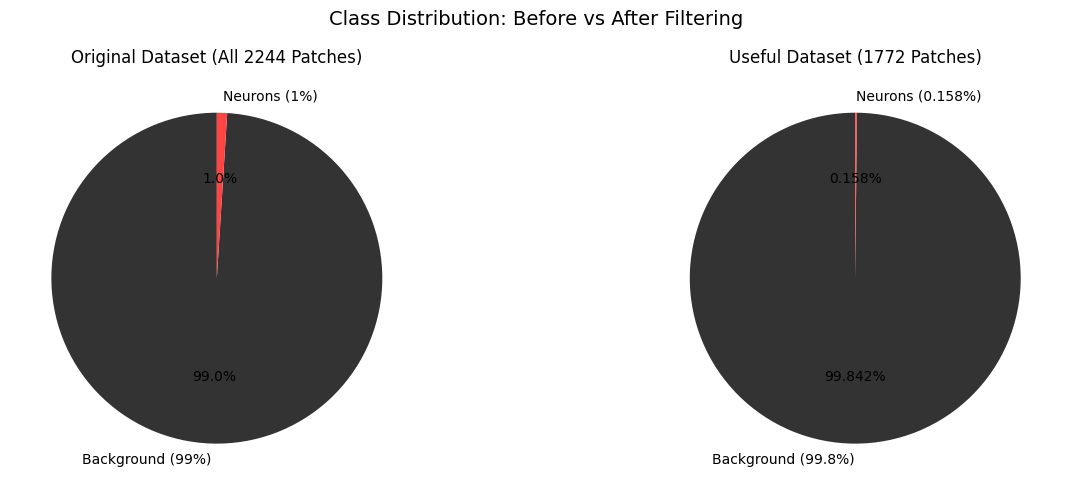

In [15]:
#  Visualize distribution comparison (before vs after)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart for original dataset (approximate)
original_sizes = [99.0, 1.0]  # background 99%, neurons 1%
axes[0].pie(original_sizes, labels=['Background (99%)', 'Neurons (1%)'], 
            colors=['#333333', '#FF4444'], autopct='%1.1f%%', startangle=90)
axes[0].set_title('Original Dataset (All 2244 Patches)')

# Pie chart for useful dataset
useful_sizes = [stats['class_0_percentage'], stats['class_255_percentage']]
axes[1].pie(useful_sizes, labels=[f'Background ({stats["class_0_percentage"]:.1f}%)', 
                                   f'Neurons ({stats["class_255_percentage"]:.3f}%)'],
            colors=['#333333', '#FF4444'], autopct='%1.3f%%', startangle=90)
axes[1].set_title(f'Useful Dataset ({stats["num_masks"]} Patches)')

plt.suptitle('Class Distribution: Before vs After Filtering', fontsize=14)
plt.tight_layout()
plt.savefig("../outputs/useful_vs_original_comparison.png", dpi=150, bbox_inches='tight')
plt.show()


In [16]:
# Additional analysis - distribution by patch type
print("\n" + "=" * 70)
print("DISTRIBUTION BY PATCH TYPE")
print("=" * 70)

# Separate neurons-only vs vessels-only
neurons_mask_indices = []
vessels_mask_indices = []

for i, mask in enumerate(masks):
    if np.sum(mask == 255) > 0:
        neurons_mask_indices.append(i)
    else:
        vessels_mask_indices.append(i)

print(f"Neuron patches: {len(neurons_mask_indices)}")
print(f"Vessels-only patches: {len(vessels_mask_indices)}")

# Calculate average neuron voxels for neuron patches
if len(neurons_mask_indices) > 0:
    neuron_patch_voxels = [stats['class_255_per_mask'][i] for i in neurons_mask_indices]
    print(f"\nNeuron patches statistics:")
    print(f"  Min neuron voxels: {min(neuron_patch_voxels)}")
    print(f"  Max neuron voxels: {max(neuron_patch_voxels)}")
    print(f"  Mean neuron voxels: {np.mean(neuron_patch_voxels):.2f}")
    print(f"  Median neuron voxels: {np.median(neuron_patch_voxels):.2f}")




DISTRIBUTION BY PATCH TYPE
Neuron patches: 1739
Vessels-only patches: 33

Neuron patches statistics:
  Min neuron voxels: 1
  Max neuron voxels: 6849
  Mean neuron voxels: 422.84
  Median neuron voxels: 190.00


In [17]:
# Cell 17: Final verification
print("\n" + "=" * 70)
print("FINAL VERIFICATION")
print("=" * 70)

# Check that we have no pure background patches (should be 0)
pure_background = sum(1 for mask in masks if np.sum(mask == 255) == 0 and np.sum(mask == 0) == mask.size)
print(f"Pure background patches (should be 0): {pure_background}")

# Check that all masks contain only 0 and 255
invalid_masks = 0
for mask in masks:
    unique = np.unique(mask)
    if not np.all((unique == 0) | (unique == 255)):
        invalid_masks += 1
print(f"Invalid masks (values other than 0,255): {invalid_masks}")

if pure_background == 0 and invalid_masks == 0:
    print("\n✅ Dataset is clean and ready for training!")
else:
    print("\n❌ Issues detected. Please check the dataset.")




FINAL VERIFICATION
Pure background patches (should be 0): 33
Invalid masks (values other than 0,255): 0

❌ Issues detected. Please check the dataset.


In [18]:
# Display final statistics table
print("\n" + "=" * 70)
print("FINAL STATISTICS TABLE")
print("=" * 70)
print(f"{'Metric':<40} {'Value':>20}")
print("-" * 60)
print(f"{'Total useful patches':<40} {stats['num_masks']:>20}")
print(f"{'Patches with neurons':<40} {stats['masks_with_neurons']:>20}")
print(f"{'Vessels-only patches':<40} {stats['masks_without_neurons']:>20}")
print(f"{'Total neuron voxels':<40} {stats['total_class_255']:>20,}")
print(f"{'Total background voxels':<40} {stats['total_class_0']:>20,}")
print(f"{'Class ratio (BG:Neurons)':<40} {stats['class_ratio']:>20.2f}")
print(f"{'Background percentage':<40} {stats['class_0_percentage']:>19.4f}%")
print(f"{'Neuron percentage':<40} {stats['class_255_percentage']:>19.6f}%")
print("=" * 70)


FINAL STATISTICS TABLE
Metric                                                  Value
------------------------------------------------------------
Total useful patches                                     1772
Patches with neurons                                     1739
Vessels-only patches                                       33
Total neuron voxels                                   735,326
Total background voxels                           463,783,842
Class ratio (BG:Neurons)                               630.72
Background percentage                                99.8417%
Neuron percentage                                   0.158298%
